# Food Image Classifier

TME 6015 Assignment 2. The task is to classify recipe blog photos into six classes: cake, cookies, pasta, salad, soup and stir_fry.

The notebook trains two models on the same data:

1. **Model 1:** a CNN built from scratch. It starts from a standard baseline, and each change after that is tested on the validation set.
2. **Model 2:** transfer learning from a pre-trained backbone.

## Dataset

I built the dataset from the main photo of recipes on seven recipe blogs: recipetineats, budgetbytes, cafedelites, loveandlemons, omnivorescookbook, sugarspunrun and natashaskitchen. A script downloaded each photo through the blogs' recipe plugin API. It labelled each photo from the recipe's category, used the title as a fallback, and skipped recipes that didn't match exactly one class. To keep the classes balanced, I capped each class at 150 photos per site and 300 in total.

| Site | Cake | Cookies | Pasta | Salad | Soup | Stir fry | Total |
| --- | --- | --- | --- | --- | --- | --- | --- |
| budgetbytes | 32 | 25 | 128 | 133 | 89 | 17 | 424 |
| recipetineats | 67 | 25 | 78 | 121 | 68 | 45 | 404 |
| sugarspunrun | 147 | 148 | 0 | 0 | 0 | 0 | 295 |
| loveandlemons | 28 | 48 | 56 | 0 | 80 | 6 | 218 |
| omnivorescookbook | 10 | 5 | 0 | 0 | 38 | 117 | 170 |
| cafedelites | 15 | 9 | 29 | 46 | 25 | 9 | 133 |
| natashaskitchen | 0 | 28 | 0 | 0 | 0 | 7 | 35 |
| **Total** | **299** | **288** | **291** | **300** | **300** | **201** | **1,679** |

A cleaning script then removed photos whose title showed they weren't one dish of the class, like roundup posts, spaghetti squash as pasta and ice cream as cookies, and dropped near-duplicate images. That left 1,679 of the 1,694 downloaded photos. I split them 70/15/15 into train, validation and test, keeping each site's share of every class the same in all three splits.

| Step | Images |
| --- | --- |
| Downloaded | 1,694 |
| Removed by cleaning | 15 |
| Kept | 1,679 |
| Train / validation / test (70/15/15) | 1,175 / 252 / 252 |

The two major concerns with this dataset are:

- Some classes look alike. Cake and cookies can look similar, and so can stir fry and pasta.
- Some sites supply most of a class, so a model might learn a site's photo style rather than what the food actually is.

With only about 200 photos per class, a CNN trained from scratch may struggle, so I expect the pretrained model to do better.

## 1. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, f1_score
from tensorflow.keras import layers

In [2]:
ROOT = Path.cwd()  # the notebook runs from the repo root
SPLIT = ROOT / "data" / "split"
CLASS_NAMES = ["cake", "cookies", "pasta", "salad", "soup", "stir_fry"]
NUM_CLASSES = len(CLASS_NAMES)
IMG_SIZE = (224, 224)
INPUT_SHAPE = IMG_SIZE + (3,)
BATCH_SIZE = 32
SEED = 42

tf.keras.utils.set_random_seed(SEED)

## 2. Data

### 2.1 Loading

The split script wrote one folder per class inside `train/`, `val/` and `test/`.

In [3]:
def load(split, training=False):
    ds = tf.keras.utils.image_dataset_from_directory(
        SPLIT / split,
        class_names=CLASS_NAMES,
        label_mode="int",
        image_size=IMG_SIZE,
        crop_to_aspect_ratio=True,
        batch_size=None,
        shuffle=False,
    )
    files = ds.file_paths
    ds = ds.cache()
    if training:
        ds = ds.shuffle(len(files), seed=SEED)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE), files


train_ds, train_files = load("train", training=True)
val_ds, val_files = load("val")
test_ds, test_files = load("test")

train_ds.element_spec

Found 1175 files belonging to 6 classes.
Found 252 files belonging to 6 classes.
Found 252 files belonging to 6 classes.


(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None),
 TensorSpec(shape=(None,), dtype=tf.int32, name=None))

### 2.2 Sanity check

One batch of training images with their labels. This confirms that the labels match the images and that the centre crop keeps the food in frame.

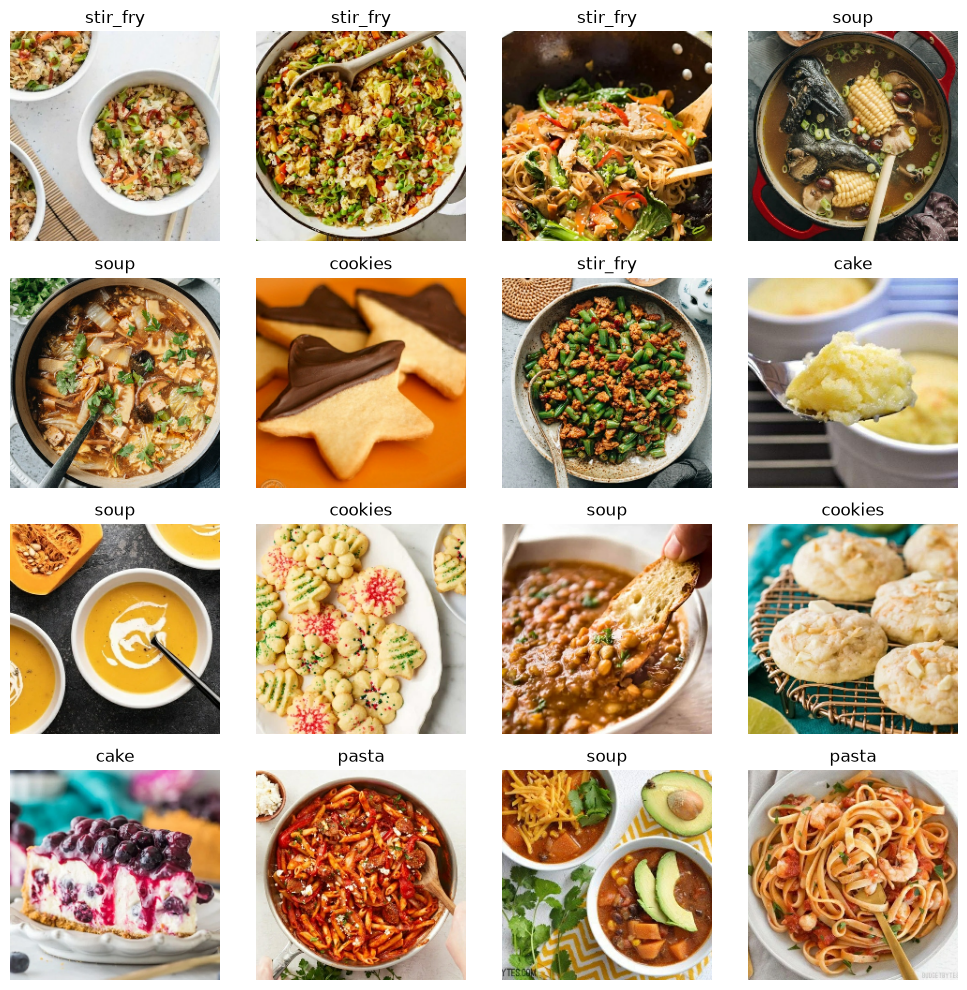

In [4]:
def show_images(images, titles, cols=4):
    rows = int(np.ceil(len(titles) / cols))
    plt.figure(figsize=(2.5 * cols, 2.5 * rows))
    for i, title in enumerate(titles):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(np.asarray(images[i]).astype("uint8"))
        plt.title(title)
        plt.axis("off")
    plt.tight_layout()
    plt.show()


images, labels = next(iter(train_ds))
show_images(images, [CLASS_NAMES[i] for i in labels[:16]])

### 2.3 Class weights

Stir fry has about two thirds as many training images as the other classes. Without a correction the model gains less from learning it. Each class weight is `total / (classes x class count)`, the same formula as sklearn's `"balanced"` option. A class of average size gets a weight of 1, and smaller classes get more.

In [5]:
train_counts = {i: len(list((SPLIT / "train" / name).glob("*.jpg"))) for i, name in enumerate(CLASS_NAMES)}
total = sum(train_counts.values())
class_weight = {i: total / (NUM_CLASSES * count) for i, count in train_counts.items()}

pd.DataFrame({
    "class": CLASS_NAMES,
    "train images": train_counts.values(),
    "weight": [round(w, 2) for w in class_weight.values()],
})

,class,train images,weight
0,cake,210,0.93
1,cookies,202,0.97
2,pasta,204,0.96
3,salad,210,0.93
4,soup,210,0.93
5,stir_fry,139,1.41


## 3. Shared components

### 3.1 Augmentation

With about 200 images per class, a model can memorise the training photos within a few epochs. Random changes give it a slightly different version of each photo every epoch, so it has to learn what the food looks like instead of the exact pixels.

- **Horizontal flip:** a mirrored dish is still the same dish. No vertical flip, since upside down plates do not appear in blog photos.
- **Rotation up to 18 degrees:** covers a tilted camera.
- **Zoom up to 10%:** covers close ups against wide table shots, which differ a lot between sites.
- **Contrast up to 10%:** covers different lighting and editing styles. Each blog has its own look, so this also weakens site style as a shortcut.

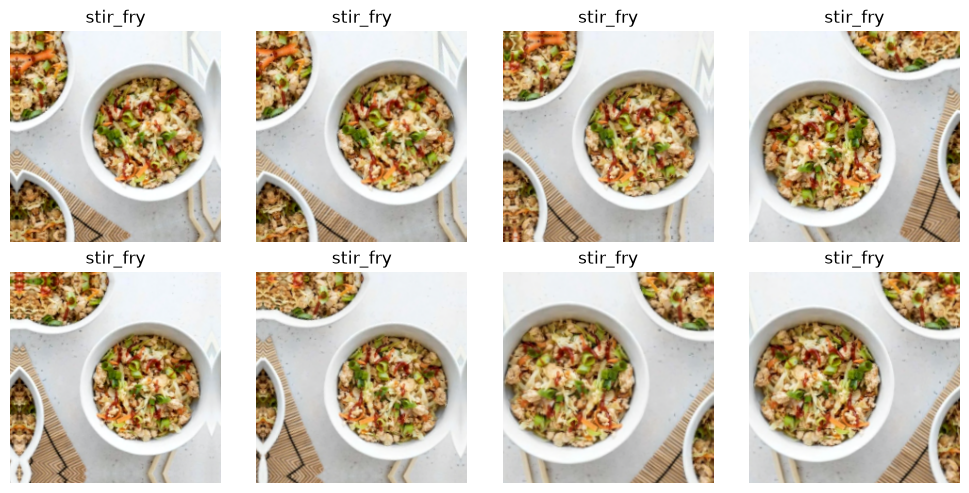

In [6]:
augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),  # fraction of a full turn: 0.05 is 18 degrees
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name="augmentation")

show_images(
    [augmentation(images[:1], training=True)[0] for _ in range(8)],
    [CLASS_NAMES[labels[0]]] * 8,
)

### 3.2 Training

`train` compiles and fits a model with the same settings for every model.

- **Loss:** sparse categorical cross entropy on logits. Labels are integers, and every model ends in `Dense(6)` with no activation.
- **Optimizer:** Adam with a default learning rate of 0.001.
- **Class weights** from section 2.3.
- **Early stopping** on validation loss with a patience of 5 epochs. It restores the weights from the best epoch, so the returned model is the best one seen and not the last.

`plot_curves` draws training and validation accuracy and loss. The dotted line marks the epoch with the lowest validation loss, which is the epoch early stopping keeps.

`summarize_runs` turns training histories into a table: the best epoch, where training stopped, and the scores at the best epoch. The tables in section 4 come from it, so they always match the current run.

In [7]:
def train(model, epochs=30, learning_rate=1e-3, patience=5):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=["accuracy"],
    )
    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=patience, restore_best_weights=True
    )
    return model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=epochs,
        class_weight=class_weight,
        shuffle=False,  # train_ds is already shuffled in load()
        callbacks=[early_stop],
    )


def plot_curves(history, title):
    h = history.history
    epochs = range(1, len(h["loss"]) + 1)
    best_epoch = int(np.argmin(h["val_loss"])) + 1

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, metric in zip(axes, ["accuracy", "loss"]):
        ax.plot(epochs, h[metric], label="train")
        ax.plot(epochs, h[f"val_{metric}"], label="validation")
        ax.axvline(best_epoch, color="grey", linestyle=":", label=f"best epoch ({best_epoch})")
        ax.set(title=metric.capitalize(), xlabel="Epoch")
        ax.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def summarize_runs(histories):
    rows = {}
    for name, history in histories.items():
        h = history.history
        best = int(np.argmin(h["val_loss"]))
        rows[name] = {
            "best epoch": best + 1,
            "stopped at": len(h["loss"]),
            "best val loss": h["val_loss"][best],
            "val accuracy (best epoch)": h["val_accuracy"][best],
            "train accuracy (final)": h["accuracy"][-1],
        }
    return pd.DataFrame.from_dict(rows, orient="index").round(3)

### 3.3 Evaluation

`evaluate` runs once per model on the test set and reports:

- accuracy and macro F1
- precision, recall and F1 per class
- a confusion matrix
- accuracy per source site

Each result goes into `results` for the comparison in section 6.

In [8]:
site_of = pd.read_csv(ROOT / "data" / "split.csv").set_index("filename")["source_site"]
results = {}


def evaluate(model, ds, files, title):
    y_true = np.concatenate([y for _, y in ds])
    y_pred = model.predict(ds, verbose=0).argmax(axis=1)

    acc = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average="macro")
    print(f"{title}: accuracy {acc:.3f}, macro F1 {macro_f1:.3f}\n")
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=3, zero_division=0))

    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred, display_labels=CLASS_NAMES, xticks_rotation=45, cmap="Blues", colorbar=False
    )
    plt.title(title)
    plt.show()

    per_site = (
        pd.DataFrame({"site": site_of[[Path(f).name for f in files]].values, "correct": y_true == y_pred})
        .groupby("site")["correct"]
        .agg(accuracy="mean", images="size")
        .sort_values("accuracy")
    )
    display(per_site.round(3))

    return {"accuracy": acc, "macro F1": macro_f1, "parameters": model.count_params()}

## 4. Model 1: CNN from scratch

### 4.1 Architecture

Four blocks of a 3x3 convolution, ReLU and 2x2 max pooling, with the filters doubling from 32 to 256. This is the VGG pattern from the lectures: each pooling step halves the image, and doubling the filters lets later blocks hold more complex patterns. Global average pooling replaces `Flatten` to keep the head small, and dropout of 0.5 sits before the output layer.

`build_cnn` builds every version in this section. Its two switches add the changes tested during tuning, so everything else stays identical between runs.

- `batch_norm=True` puts batch normalisation between each convolution and its ReLU.
- `augment=True` puts the augmentation block from section 3.1 before rescaling.

| Hyperparameter | Value | Reason |
| --- | --- | --- |
| Image size | 224 x 224 | Standard size for CNNs and the size MobileNetV2 expects, so both models see the same input |
| Batch size | 32 | Common default that fits in memory on a laptop |
| Optimizer | Adam, learning rate 0.001 | Works well without tuning, so changes in results come from the architecture |
| Kernel size | 3x3 | Fewer weights than larger kernels, following VGG |
| Dropout | 0.5 | Top of the usual 0.2 to 0.5 range, since the small dataset makes memorising likely |

In [9]:
def build_cnn(name, batch_norm=False, augment=False):
    tf.keras.utils.set_random_seed(SEED)
    model = tf.keras.Sequential(name=name)
    model.add(tf.keras.Input(shape=INPUT_SHAPE))
    if augment:
        model.add(augmentation)  # before rescaling: the layers expect pixels from 0 to 255
    model.add(layers.Rescaling(1 / 255))

    for filters in [32, 64, 128, 256]:
        if batch_norm:
            model.add(layers.Conv2D(filters, (3, 3)))
            model.add(layers.BatchNormalization(momentum=0.9))  # default 0.99 left validation stuck at chance
            model.add(layers.ReLU())
        else:
            model.add(layers.Conv2D(filters, (3, 3), activation="relu"))
        model.add(layers.MaxPooling2D())

    model.add(layers.GlobalAveragePooling2D())
    model.add(layers.Dropout(0.5))
    model.add(layers.Dense(NUM_CLASSES))
    return model


build_cnn("cnn").summary(print_fn=print)

Model: "cnn"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───

### 4.2 Baseline (30 epochs)

The baseline trains with the default settings from section 3.2: up to 30 epochs and a patience of 5.

In [10]:
cnn_30 = build_cnn("cnn_30")
hist_cnn_30 = train(cnn_30)

Epoch 1/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 15s 402ms/step - accuracy: 0.2102 - loss: 1.7402 - val_accuracy: 0.2937 - val_loss: 1.6165
Epoch 2/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 13s 356ms/step - accuracy: 0.2996 - loss: 1.5794 - val_accuracy: 0.3254 - val_loss: 1.5593
Epoch 3/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 14s 368ms/step - accuracy: 0.3345 - loss: 1.4967 - val_accuracy: 0.3373 - val_loss: 1.6256
Epoch 4/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 13s 339ms/step - accuracy: 0.3413 - loss: 1.5154 - val_accuracy: 0.3651 - val_loss: 1.4664
Epoch 5/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 13s 339ms/step - accuracy: 0.4034 - loss: 1.3834 - val_accuracy: 0.4484 - val_loss: 1.3851
Epoch 6/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 13s 341ms/step - accuracy: 0.4383 - loss: 1.3410 - val_accuracy: 0.3730 - val_loss: 1.4076
Epoch 7/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 13s 352ms/step - accuracy: 0.4077 - loss: 1.3571 - val_accuracy: 0.4087 - val_loss: 1.3644
Epoch 8/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 13s 356ms/step - accuracy: 0.4374 - loss: 1.3173 - val_accu

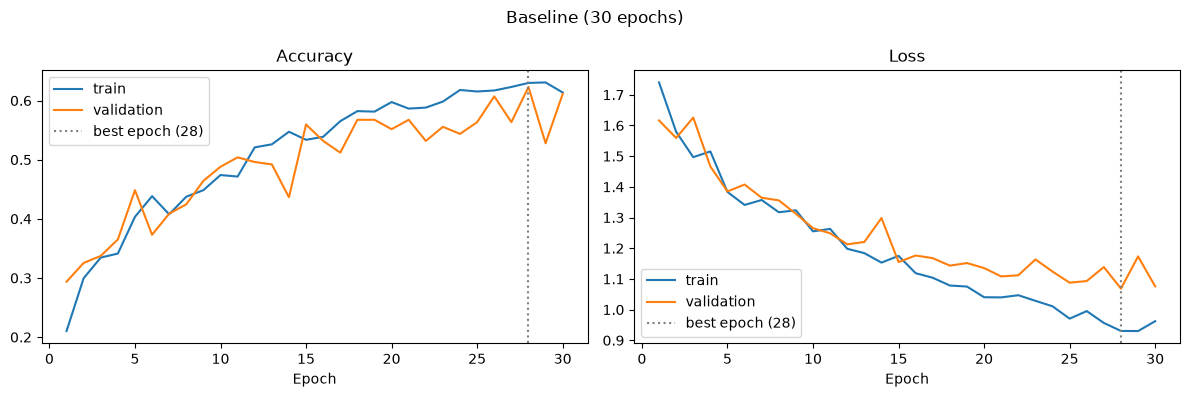

,best epoch,stopped at,best val loss,val accuracy (best epoch),train accuracy (final)
Baseline (30 epochs),28,30,1.068,0.623,0.614


In [11]:
plot_curves(hist_cnn_30, "Baseline (30 epochs)")
summarize_runs({"Baseline (30 epochs)": hist_cnn_30})

#### Interpretation

The graph and table above show that the model is still learning, but it slows down over time. Training ran for all 30 epochs because it hit the epoch limit, and the best weights came from epoch 28. The next step is to train the exact same model with a much larger number of epochs, and analyze what the curves look like.

### 4.3 Longer training (80 epochs)

The same model with a limit of 80 epochs and a patience of 8. Validation accuracy swings by several points between epochs, so a patience of 5 could stop training on one noisy epoch.

In [12]:
cnn = build_cnn("cnn")
hist_cnn = train(cnn, epochs=80, patience=8)

Epoch 1/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 20s 532ms/step - accuracy: 0.2213 - loss: 1.7386 - val_accuracy: 0.2421 - val_loss: 1.6599
Epoch 2/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 19s 526ms/step - accuracy: 0.3157 - loss: 1.5583 - val_accuracy: 0.2976 - val_loss: 1.5202
Epoch 3/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 20s 530ms/step - accuracy: 0.3379 - loss: 1.5120 - val_accuracy: 0.4127 - val_loss: 1.4756
Epoch 4/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 20s 528ms/step - accuracy: 0.3770 - loss: 1.4544 - val_accuracy: 0.3214 - val_loss: 1.4864
Epoch 5/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 19s 518ms/step - accuracy: 0.3711 - loss: 1.4757 - val_accuracy: 0.3135 - val_loss: 1.4642
Epoch 6/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 21s 556ms/step - accuracy: 0.4196 - loss: 1.3771 - val_accuracy: 0.3690 - val_loss: 1.4211
Epoch 7/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 20s 533ms/step - accuracy: 0.4204 - loss: 1.3482 - val_accuracy: 0.4444 - val_loss: 1.3237
Epoch 8/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 20s 546ms/step - accuracy: 0.4349 - loss: 1.3004 - val_accu

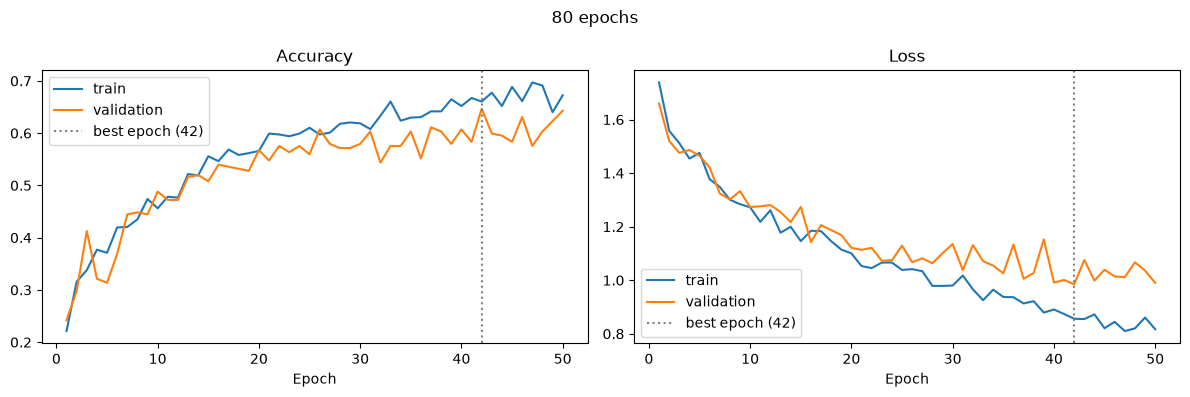

,best epoch,stopped at,best val loss,val accuracy (best epoch),train accuracy (final)
Baseline (30 epochs),28,30,1.068,0.623,0.614
80 epochs,42,50,0.985,0.647,0.672


In [13]:
plot_curves(hist_cnn, "80 epochs")
summarize_runs({"Baseline (30 epochs)": hist_cnn_30, "80 epochs": hist_cnn})

#### Interpretation

Looking at the graph above, training stopped at the 50th epoch, and the 42nd was the best. This is the limit of these settings. A small gap between training and validation also starts to open after epoch 40, so the model is starting to memorise. But the main problem is still the slow and unsteady learning, so adding Batch Normalization is the next improvement to try.

Lowering the learning rate would make training steadier but even slower, while Batch Normalization can fix both the slow and the unsteady learning, so I tried it first.

### 4.4 Batch normalisation

Each block becomes convolution, batch normalisation, ReLU, then pooling. The first run used the default momentum of 0.99, and validation accuracy got stuck at 0.17 because the model predicted the same class for every image. Batch normalisation uses a running average during validation, and with 0.99 that average updated too slowly to keep up with the weights. Changing the momentum to 0.9 makes it update faster, which fixed the problem.

In [14]:
cnn_bn = build_cnn("cnn_bn", batch_norm=True)
hist_cnn_bn = train(cnn_bn, epochs=80, patience=8)

Epoch 1/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 28s 715ms/step - accuracy: 0.3191 - loss: 1.8077 - val_accuracy: 0.1905 - val_loss: 2.5250
Epoch 2/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 27s 725ms/step - accuracy: 0.4417 - loss: 1.4618 - val_accuracy: 0.4405 - val_loss: 1.4680
Epoch 3/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 28s 755ms/step - accuracy: 0.4553 - loss: 1.3787 - val_accuracy: 0.5000 - val_loss: 1.3774
Epoch 4/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 28s 749ms/step - accuracy: 0.4970 - loss: 1.2678 - val_accuracy: 0.4683 - val_loss: 1.3417
Epoch 5/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 28s 752ms/step - accuracy: 0.5209 - loss: 1.2563 - val_accuracy: 0.4405 - val_loss: 1.3618
Epoch 6/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 27s 732ms/step - accuracy: 0.5345 - loss: 1.1786 - val_accuracy: 0.4444 - val_loss: 1.3868
Epoch 7/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 29s 773ms/step - accuracy: 0.5634 - loss: 1.1433 - val_accuracy: 0.4246 - val_loss: 1.7762
Epoch 8/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 27s 741ms/step - accuracy: 0.5957 - loss: 1.1119 - val_accu

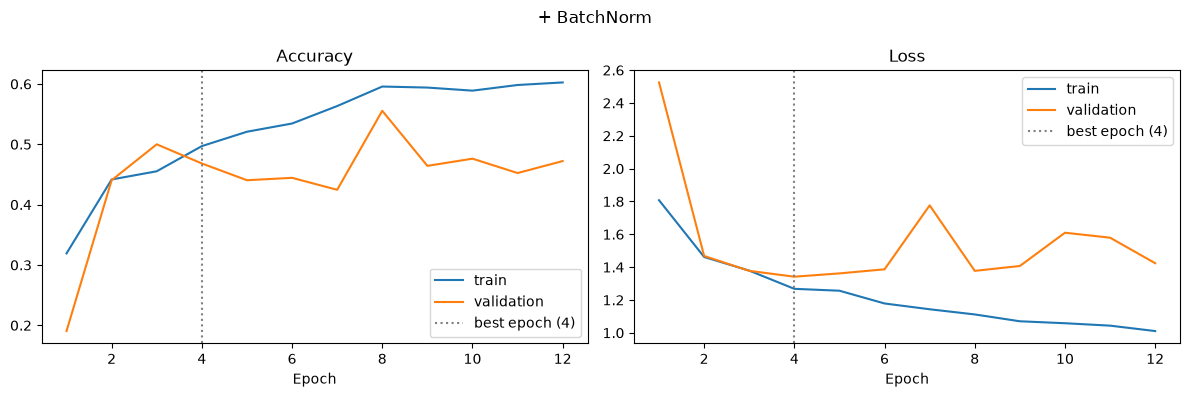

,best epoch,stopped at,best val loss,val accuracy (best epoch),train accuracy (final)
80 epochs,42,50,0.985,0.647,0.672
+ BatchNorm,4,12,1.342,0.468,0.603


In [15]:
plot_curves(hist_cnn_bn, "+ BatchNorm")
summarize_runs({"80 epochs": hist_cnn, "+ BatchNorm": hist_cnn_bn})

#### Interpretation

Batch normalisation isn't stable on this dataset. I ran it with the same settings but different random starting points, and the results changed a lot. The 80 epoch model barely changed.

| Run | Best epoch | Best val loss | Val accuracy |
| --- | --- | --- | --- |
| 80 epochs, run 1 | 42 | 0.985 | 0.647 |
| 80 epochs, run 2 | 58 | 0.918 | 0.659 |
| + BatchNorm, run 1 | 21 | 0.989 | 0.651 |
| + BatchNorm, run 2 | 4 | 1.342 | 0.468 |
| + BatchNorm, run 3 | 7 | 1.133 | 0.575 |

The 80 epoch model moved by about one point. Batch normalisation went from 0.47 to 0.65. It's also jumpy within a run. In the run above, the validation loss went from 1.39 to 1.78 in one epoch while training kept improving.

This happens because batch normalisation uses a running average during validation, and that average shifts with the last few batches. So validation jumps around, and early stopping keeps whichever epoch happens to look best early on.

Since it was unstable and never beat the 80 epoch model, I dropped it. That model also started to memorise near the end of training, so I tried augmentation next.

### 4.5 Augmentation

The 80 epoch model from section 4.3 plus the augmentation block from section 3.1, without batch normalisation.

In [16]:
cnn_aug = build_cnn("cnn_aug", augment=True)
hist_cnn_aug = train(cnn_aug, epochs=80, patience=8)

Epoch 1/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 20s 540ms/step - accuracy: 0.2281 - loss: 1.7342 - val_accuracy: 0.2262 - val_loss: 1.7411
Epoch 2/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 20s 532ms/step - accuracy: 0.2894 - loss: 1.5872 - val_accuracy: 0.3056 - val_loss: 1.6222
Epoch 3/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 19s 519ms/step - accuracy: 0.3421 - loss: 1.5042 - val_accuracy: 0.2937 - val_loss: 1.5359
Epoch 4/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 19s 510ms/step - accuracy: 0.3566 - loss: 1.4808 - val_accuracy: 0.3294 - val_loss: 1.5626
Epoch 5/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 18s 499ms/step - accuracy: 0.4017 - loss: 1.4028 - val_accuracy: 0.3135 - val_loss: 1.4540
Epoch 6/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 19s 510ms/step - accuracy: 0.3966 - loss: 1.3949 - val_accuracy: 0.4008 - val_loss: 1.3401
Epoch 7/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 20s 530ms/step - accuracy: 0.4298 - loss: 1.3487 - val_accuracy: 0.4444 - val_loss: 1.3636
Epoch 8/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 19s 518ms/step - accuracy: 0.4204 - loss: 1.3249 - val_accu

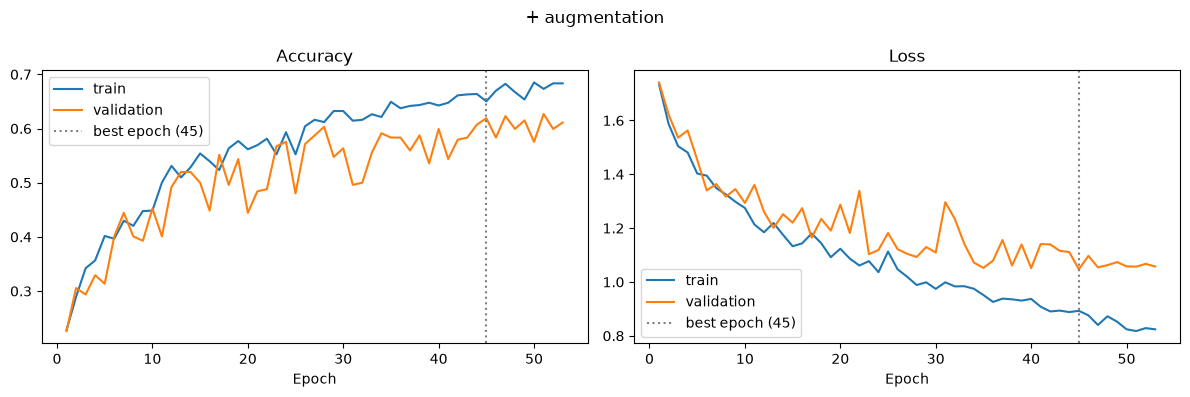

,best epoch,stopped at,best val loss,val accuracy (best epoch),train accuracy (final)
80 epochs,42,50,0.985,0.647,0.672
+ BatchNorm,4,12,1.342,0.468,0.603
+ augmentation,45,53,1.047,0.619,0.683


In [17]:
plot_curves(hist_cnn_aug, "+ augmentation")
summarize_runs({"80 epochs": hist_cnn, "+ BatchNorm": hist_cnn_bn, "+ augmentation": hist_cnn_aug})

#### Interpretation

Augmentation made the model learn more slowly and did slightly worse, with a best validation loss of 1.05 and accuracy of 0.62, compared to 0.99 and 0.65 for the 80 epoch model. It also didn't close the gap between training and validation.

Every version levels off around 60 to 65%, which looks like the limit of training from scratch on this dataset. So I kept the 80 epoch model as the final Model 1, since it has the lowest validation loss.

### 4.6 Test results

The final Model 1 is the 80 epoch version from section 4.3. It is evaluated on the test set once.

Model 1: accuracy 0.643, macro F1 0.639

              precision    recall  f1-score   support

        cake      0.557     0.756     0.642        45
     cookies      0.700     0.488     0.575        43
       pasta      0.600     0.419     0.493        43
       salad      0.717     0.733     0.725        45
        soup      0.667     0.667     0.667        45
    stir_fry      0.650     0.839     0.732        31

    accuracy                          0.643       252
   macro avg      0.649     0.650     0.639       252
weighted avg      0.648     0.643     0.636       252



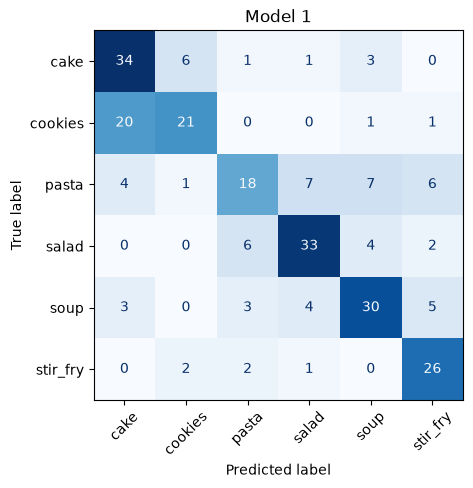

,accuracy,images
site,,
natashaskitchen.com,0.000,5
loveandlemons.com,0.531,32
budgetbytes.com,0.578,64
recipetineats.com,0.672,61
sugarspunrun.com,0.705,44
omnivorescookbook.com,0.769,26
cafedelites.com,0.800,20


In [18]:
model_1 = cnn
results["Model 1"] = evaluate(model_1, test_ds, test_files, "Model 1")

#### Interpretation

Model 1 scored 64.3% accuracy and a macro F1 of 0.639 on the test set, which is almost the same as validation (64.7%). So the tuning didn't overfit the validation set, and this is the model's real performance.

The confusion matrix shows the biggest mistake is cookies being predicted as cake (20 of 43 cookies). They're both baked and brown, and most of them come from the same site. Pasta is the weakest class because its mistakes are spread across salad, soup and stir fry, which makes sense since pasta shows up in all of those dishes. Stir fry did the best even though it has the fewest images.

The sites that supply most of one class, omnivorescookbook for stir fry and sugarspunrun for cake and cookies, score above average. This could mean the model is using the site's photo style as a shortcut, but the test set is too small per site to confirm it.

## 5. Model 2: transfer learning

### 5.1 Pre-trained model

I chose MobileNetV2 because it's small and fast enough to train on a laptop CPU, close in ImageNet accuracy to much larger models, and less likely to overfit on a dataset of this size. It's built from depthwise separable convolutions, which keep the parameter count low.

### 5.2 Feature extraction

The pre-trained base is frozen, so only the new head learns. The head matches Model 1: global average pooling, dropout of 0.5 and a dense layer with 6 outputs.

In [19]:
tf.keras.utils.set_random_seed(SEED)

base = tf.keras.applications.MobileNetV2(input_shape=INPUT_SHAPE, include_top=False, weights="imagenet")
base.trainable = False

inputs = tf.keras.Input(shape=INPUT_SHAPE)
x = augmentation(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)  # scales pixels to -1..1, what MobileNetV2 was trained on
x = base(x, training=False)  # keeps the base's BatchNorm in inference mode, also during fine-tuning
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(NUM_CLASSES)(x)

tl = tf.keras.Model(inputs, outputs, name="tl")
tl.summary(print_fn=print)

Model: "tl"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │    

In [20]:
hist_tl = train(tl, epochs=80, patience=8)

Epoch 1/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 9s 216ms/step - accuracy: 0.3787 - loss: 1.6790 - val_accuracy: 0.6429 - val_loss: 0.9923
Epoch 2/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 7s 201ms/step - accuracy: 0.6213 - loss: 1.0011 - val_accuracy: 0.7262 - val_loss: 0.7993
Epoch 3/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 7s 202ms/step - accuracy: 0.6800 - loss: 0.8803 - val_accuracy: 0.7460 - val_loss: 0.7311
Epoch 4/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 7s 201ms/step - accuracy: 0.7166 - loss: 0.7772 - val_accuracy: 0.7500 - val_loss: 0.7125
Epoch 5/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 7s 200ms/step - accuracy: 0.7370 - loss: 0.7268 - val_accuracy: 0.7976 - val_loss: 0.6145
Epoch 6/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 8s 205ms/step - accuracy: 0.7574 - loss: 0.6375 - val_accuracy: 0.7817 - val_loss: 0.6608
Epoch 7/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 7s 201ms/step - accuracy: 0.7864 - loss: 0.6072 - val_accuracy: 0.7778 - val_loss: 0.6635
Epoch 8/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 7s 202ms/step - accuracy: 0.7847 - loss: 0.5789 - val_accuracy: 0.

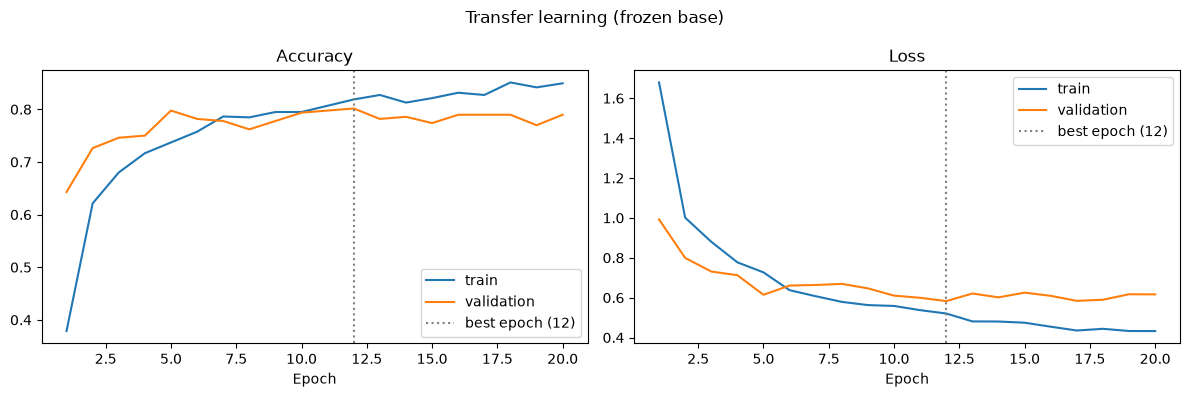

,best epoch,stopped at,best val loss,val accuracy (best epoch),train accuracy (final)
Model 1 (80 epochs),42,50,0.985,0.647,0.672
Transfer learning (frozen),12,20,0.583,0.802,0.849


In [21]:
plot_curves(hist_tl, "Transfer learning (frozen base)")
summarize_runs({"Model 1 (80 epochs)": hist_cnn, "Transfer learning (frozen)": hist_tl})

#### Interpretation

Transfer learning did much better than Model 1. Its best validation loss was 0.58 with an accuracy of 0.80, compared to 0.99 and 0.65 for the 80 epoch model. It also got there much faster. After just one epoch it was already at 0.64, about the same as Model 1's best, and training stopped at the 20th epoch with the 12th as the best.

This is because the base was already trained on over a million images, so it already knows edges, textures and shapes. Only the new head had to learn, which is 7,686 weights compared to almost 390,000 in Model 1.

### 5.3 Test results

The final Model 2 is evaluated on the test set once.

Model 2: accuracy 0.778, macro F1 0.774

              precision    recall  f1-score   support

        cake      0.755     0.889     0.816        45
     cookies      0.914     0.744     0.821        43
       pasta      0.694     0.581     0.633        43
       salad      0.842     0.711     0.771        45
        soup      0.830     0.867     0.848        45
    stir_fry      0.651     0.903     0.757        31

    accuracy                          0.778       252
   macro avg      0.781     0.783     0.774       252
weighted avg      0.788     0.778     0.776       252



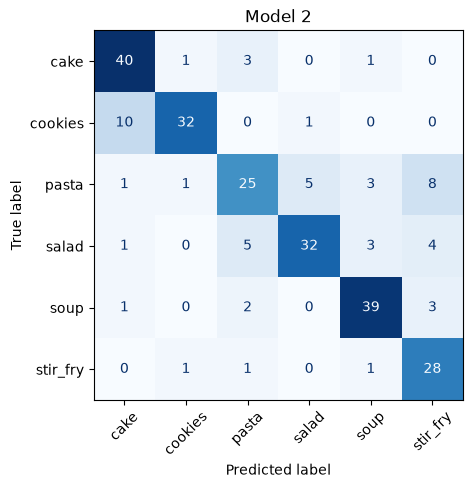

,accuracy,images
site,,
natashaskitchen.com,0.600,5
budgetbytes.com,0.750,64
recipetineats.com,0.754,61
omnivorescookbook.com,0.769,26
loveandlemons.com,0.781,32
cafedelites.com,0.800,20
sugarspunrun.com,0.864,44


In [22]:
model_2 = tl
results["Model 2"] = evaluate(model_2, test_ds, test_files, "Model 2")

#### Interpretation

Model 2 scored 77.8% accuracy and a macro F1 of 0.774 on the test set, close to its validation accuracy of 80%. That's about 13 points better than Model 1.

Pasta is still the weakest class, since it overlaps with salad, soup and stir fry. But cookies improved a lot, with recall going from 0.49 in Model 1 to 0.74, so it mixes up cookies and cake much less. Accuracy is also more even across sites, from 0.75 to 0.86 compared to 0.53 to 0.80 for Model 1, which suggests it relies less on each site's photo style.

## 6. Comparison

| | Model 1 | Model 2 |
| --- | --- | --- |
| Base | 4 conv blocks from scratch | MobileNetV2, pre-trained and frozen |
| Trainable parameters | 389,958 | 7,686 |
| Augmentation | No | Yes |
| Best epoch | 42 | 12 |
| Best val loss | 0.985 | 0.583 |
| Test accuracy | 0.643 | 0.778 |
| Test macro F1 | 0.639 | 0.774 |

Both models used the same head and training settings, so the main difference is the base. Model 1 had to learn everything from 1,175 photos, learned slowly and levelled off around 65%. Model 2 already knew edges, textures and shapes from ImageNet, so it learned faster, trained far fewer weights and scored about 13 points higher on the test set.

## 7. Use of generative AI

- Claude helped write the scripts to download, clean and split the images.
- Claude helped design the data loader, the class weight formula and the augmentation block.
- Claude diagnosed the first batch normalisation run, where validation was stuck at chance, and suggested a momentum of 0.9.
- Claude cleaned up the wording of my interpretations and restructured this notebook.

Yes, I used generative AI again. In the previous assignment I used it to write the code for my plots and to polish my interpretations, either by adding detail or by explaining concepts I wasn't familiar with. That worked well, so I used it the same way here. It helped me write scripts for websites with APIs I didn't know, clean and split the dataset, turn repeated code into reusable functions, and understand why batch normalisation failed the first time. The decisions and interpretations are still mine, and I checked everything it produced by running it  multiple times and reading the output.